# 03b · More feature engineering: peer-group-relative activity & activity composition

Notebook 03 found that aggregates, velocity and window ratios did not beat seed-to-seed noise. Two more feature
families that work on anonymised data and have a clear fraud rationale:

* **Peer-group-relative activity.** "A student moving 50× the money of a typical student" is a classic fraud signal:
  the same activity level is normal for one customer segment and suspicious for another. For key activity columns:
  `peer_<col> = log1p(value) − mean log1p(value) of the same occupation × income band`, i.e. how many log-units the
  account sits above its peers. Segment means come from **dev rows only** (no labels involved); segments with
  < 50 dev accounts fall back to the overall mean.
* **Activity composition.** Each long-window transaction column as a **share of the account's total**, plus the
  **entropy** of that mix (how many different transaction types the account uses) and the **largest share**. A
  mule that only receives and forwards should have a narrow, concentrated mix regardless of volume.

**Protocol.** The model is now fixed, so features are judged with the **final tuned model** (`src/train.py` params)
rather than notebook 03's untuned baseline: 3 seeds × 5-fold CV on dev, Platt-calibrated, same holdout.
Same selection rule: a variant must beat the reference by more than the seed-to-seed noise.

In [1]:
import sys; sys.path.insert(0, '..')
from time import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix
from src.data import DataLoader, TARGET
from src.features import FeatureBuilder
from src.model import XGBCV, PlattCalibrator, evaluate
from src.train import XGB_TUNED, WEIGHT_POWER

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format, 'display.width', 200)

train = DataLoader().load('train')
y = train[TARGET]
X = FeatureBuilder().fit_transform(train)
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)   # same split as 02–05
y_dev, y_hold = y.loc[idx_dev], y.loc[idx_hold]
print(f'{X.shape[1]} base features (the shipped FeatureBuilder)')

156 base features (the shipped FeatureBuilder)


## 0. Harness (as in notebooks 03/04)

In [2]:
RESULTS, RUNS, MODELS = {}, {}, {}

def f1_threshold(y_true, p):
    pr, rc, thr = precision_recall_curve(y_true, p)
    return thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]

def run(name, Xv, seeds=(0, 1, 2)):
    t, runs, rows = time(), [], []
    Xd, Xh = Xv.loc[idx_dev], Xv.loc[idx_hold]
    for s in seeds:
        cv = XGBCV(XGB_TUNED, weight_power=WEIGHT_POWER, seed=s).fit(Xd, y_dev)
        cal = PlattCalibrator().fit(cv.oof_, y_dev)
        o, h = cal.predict(cv.oof_), cal.predict(cv.predict_proba(Xh))
        runs.append((o, h))
        rows.append({**{f'oof_{k}': v for k, v in evaluate(y_dev, o).items()}, **{f'hold_{k}': v for k, v in evaluate(y_hold, h).items()}})
    r = pd.DataFrame(rows)
    RESULTS[name], RUNS[name], MODELS[name] = pd.concat([r.mean(), r.std().add_suffix('_std')]), runs, cv
    m = RESULTS[name]
    print(f'{name:<34} {Xv.shape[1]:>4} feats | OOF PR-AUC {m.oof_pr_auc:.4f}±{m.oof_pr_auc_std:.4f}  log-loss {m.oof_log_loss:.5f}±{m.oof_log_loss_std:.5f}'
          f' | holdout PR-AUC {m.hold_pr_auc:.4f}  log-loss {m.hold_log_loss:.5f} | {time() - t:.0f}s')

def within_noise(a, b):
    return a.oof_log_loss - b.oof_log_loss <= max(a.oof_log_loss_std, b.oof_log_loss_std)

def plot_confusions(names, ncols=4):
    nrows = -(-len(names) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows), squeeze=False)
    for ax, n in zip(axes.flat, names):
        oof, hold = RUNS[n][-1]
        t = f1_threshold(y_dev, oof)
        cm = confusion_matrix(y_hold, hold >= t)
        ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=11, color='white' if v > 1000 else 'black')
        tn, fp, fn, tp = cm.ravel()
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'])
        ax.set_title(f'{n}\nP={tp / max(tp + fp, 1):.3f} R={tp / (tp + fn):.3f} @t={t:.2f}', fontsize=9)
    for ax in axes.flat[len(names):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

run('B. shipped features (reference)', X)

B. shipped features (reference)     156 feats | OOF PR-AUC 0.9489±0.0009  log-loss 0.01290±0.00009 | holdout PR-AUC 0.9533  log-loss 0.01251 | 86s


## 1. Peer-group-relative activity
Segment = `occupation × income band` (the two named demographic fields a bank would naturally segment on).
Activity columns = the transaction / login columns with the strongest mule signal in the EDA, plus the total over
the transaction block.

In [3]:
TXN_BLOCK = [c for c in X.columns if c.startswith('txn_') and int(c[4:]) <= 76]
ACTIVITY = ['txn_5', 'txn_6', 'txn_11', 'txn_12', 'txn_73', 'txn_74', 'txn_75', 'txn_76', 'txn_80', 'txn_81',
            'others_21', 'others_22', 'others_25', 'others_26', 'txn_sum']
segment = X.occupation.astype(str) + ' | income ' + X.income.astype(str)
seg_n = segment.loc[idx_dev].value_counts()
print(f'{segment.nunique()} segments; {(seg_n >= 50).sum()} have ≥ 50 dev accounts (covering {seg_n[seg_n >= 50].sum() / len(idx_dev):.1%} of dev rows)')

def add_peer_features(Xf):
    Xf = Xf.copy()
    act = np.log1p(Xf[TXN_BLOCK].sum(axis=1, min_count=1).to_frame('txn_sum').join(Xf[ACTIVITY[:-1]]).clip(lower=0))
    big = seg_n[seg_n >= 50].index
    for c in ACTIVITY:
        seg_mean = act.loc[idx_dev, c].groupby(segment.loc[idx_dev]).mean().reindex(big)    # dev rows only
        ref = segment.map(seg_mean).fillna(act.loc[idx_dev, c].mean())
        Xf[f'peer_{c}'] = act[c] - ref
    return Xf

X_peer = add_peer_features(X)
run('P. + peer-relative activity', X_peer)

59 segments; 32 have ≥ 50 dev accounts (covering 99.7% of dev rows)


P. + peer-relative activity         171 feats | OOF PR-AUC 0.9475±0.0008  log-loss 0.01306±0.00006 | holdout PR-AUC 0.9522  log-loss 0.01263 | 89s


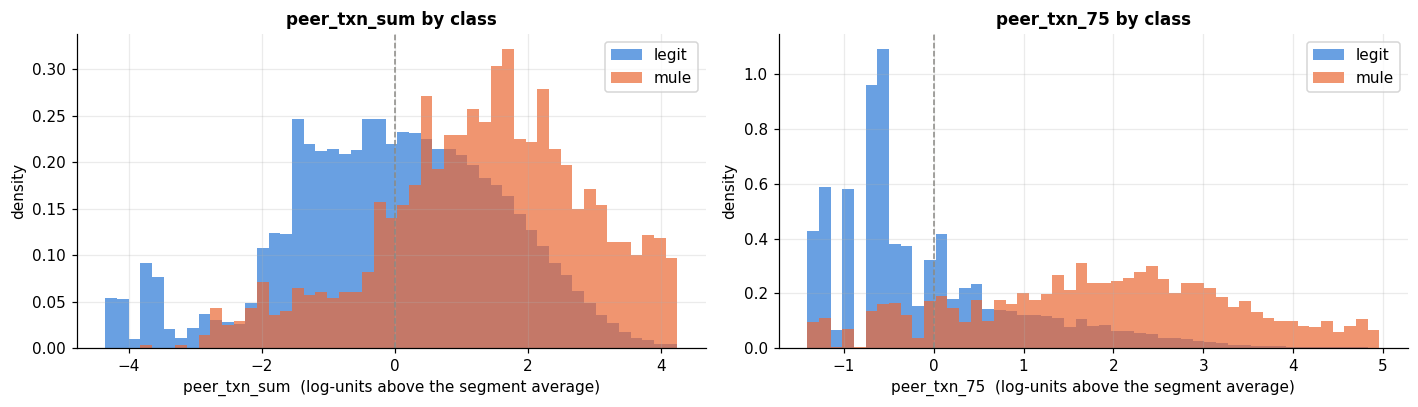

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, c in zip(axes, ['peer_txn_sum', 'peer_txn_75']):
    bins = np.linspace(X_peer[c].quantile(.005), X_peer[c].quantile(.995), 50)
    ax.hist(X_peer.loc[y == 0, c].dropna(), bins=bins, color=BLUE, alpha=.7, density=True, label='legit')
    ax.hist(X_peer.loc[y == 1, c].dropna(), bins=bins, color=ORANGE, alpha=.7, density=True, label='mule')
    ax.axvline(0, color=GRAY, ls='--', lw=1)
    ax.set(xlabel=f'{c}  (log-units above the segment average)', ylabel='density', title=f'{c} by class'); ax.legend()
plt.tight_layout(); plt.show()

## 2. Activity composition
Long-window columns of the 28+ nested pairs (notebook 03) = a profile of *which* transaction types the account uses.

In [5]:
LONG = [f'txn_{a + 1}' for a in range(1, 77, 2)
        if f'txn_{a}' in X and f'txn_{a + 1}' in X and (X[f'txn_{a + 1}'] >= X[f'txn_{a}'])[X[f'txn_{a}'].notna()].mean() > .98]
print(f'{len(LONG)} long-window columns used for the composition')

def add_composition(Xf):
    Xf = Xf.copy()
    blk = Xf[LONG].clip(lower=0)
    tot = blk.sum(axis=1, min_count=1)
    share = blk.div(tot.where(tot > 0), axis=0)                       # NaN when no activity / no record
    for c in LONG:
        Xf[f'share_{c}'] = share[c]
    p = share.fillna(0).to_numpy()
    ent = -(p * np.log(np.where(p > 0, p, 1))).sum(axis=1)
    Xf['txn_entropy'] = pd.Series(ent, index=Xf.index).where(tot > 0)
    Xf['txn_top_share'] = share.max(axis=1)
    return Xf

X_comp = add_composition(X)
run('Q. + activity composition', X_comp)

32 long-window columns used for the composition


Q. + activity composition           190 feats | OOF PR-AUC 0.9476±0.0008  log-loss 0.01307±0.00008 | holdout PR-AUC 0.9529  log-loss 0.01256 | 174s


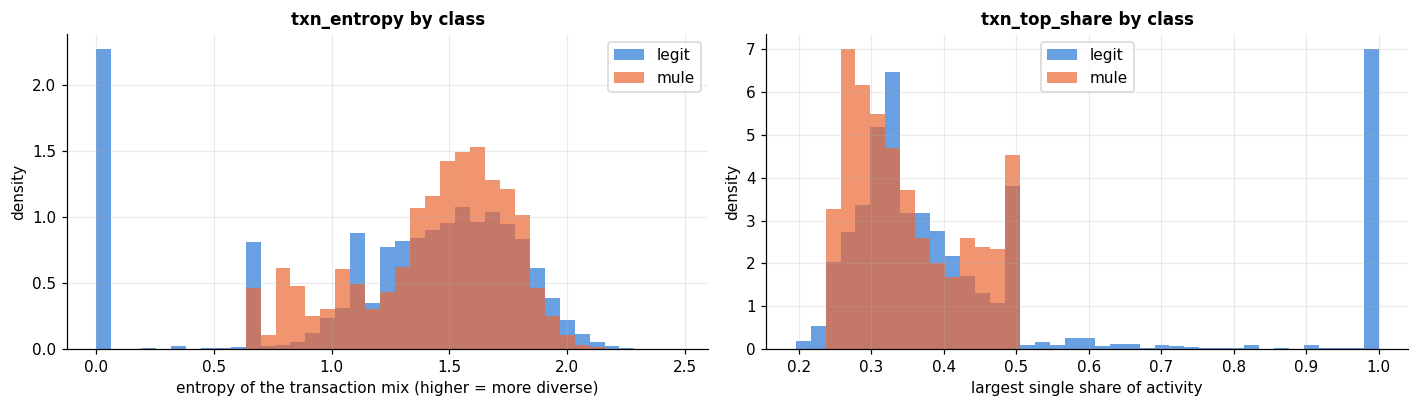

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, c, lab in zip(axes, ['txn_entropy', 'txn_top_share'], ['entropy of the transaction mix (higher = more diverse)', 'largest single share of activity']):
    bins = np.linspace(X_comp[c].min(), X_comp[c].max(), 40)
    ax.hist(X_comp.loc[y == 0, c].dropna(), bins=bins, color=BLUE, alpha=.7, density=True, label='legit')
    ax.hist(X_comp.loc[y == 1, c].dropna(), bins=bins, color=ORANGE, alpha=.7, density=True, label='mule')
    ax.set(xlabel=lab, ylabel='density', title=f'{c} by class'); ax.legend()
plt.tight_layout(); plt.show()

## 3. Both, and the verdict

In [7]:
run('R. + peer + composition', add_composition(X_peer))

R. + peer + composition             205 feats | OOF PR-AUC 0.9477±0.0014  log-loss 0.01311±0.00012 | holdout PR-AUC 0.9527  log-loss 0.01252 | 214s


In [8]:
res = pd.DataFrame(RESULTS).T
ref = res.loc['B. shipped features (reference)']
res['Δ OOF log-loss vs B'] = res.oof_log_loss - ref.oof_log_loss
res['beats B beyond noise'] = [(r.oof_log_loss < ref.oof_log_loss) and not within_noise(ref, r) for _, r in res.iterrows()]
res[['oof_pr_auc', 'oof_pr_auc_std', 'oof_log_loss', 'oof_log_loss_std', 'Δ OOF log-loss vs B', 'beats B beyond noise', 'hold_pr_auc', 'hold_log_loss']]

,oof_pr_auc,oof_pr_auc_std,oof_log_loss,oof_log_loss_std,Δ OOF log-loss vs B,beats B beyond noise,hold_pr_auc,hold_log_loss
B. shipped features (reference),0.9489,0.0009,0.0129,0.0001,0.0000,False,0.9533,0.0125
P. + peer-relative activity,0.9475,0.0008,0.0131,0.0001,0.0002,False,0.9522,0.0126
Q. + activity composition,0.9476,0.0008,0.0131,0.0001,0.0002,False,0.9529,0.0126
R. + peer + composition,0.9477,0.0014,0.0131,0.0001,0.0002,False,0.9527,0.0125


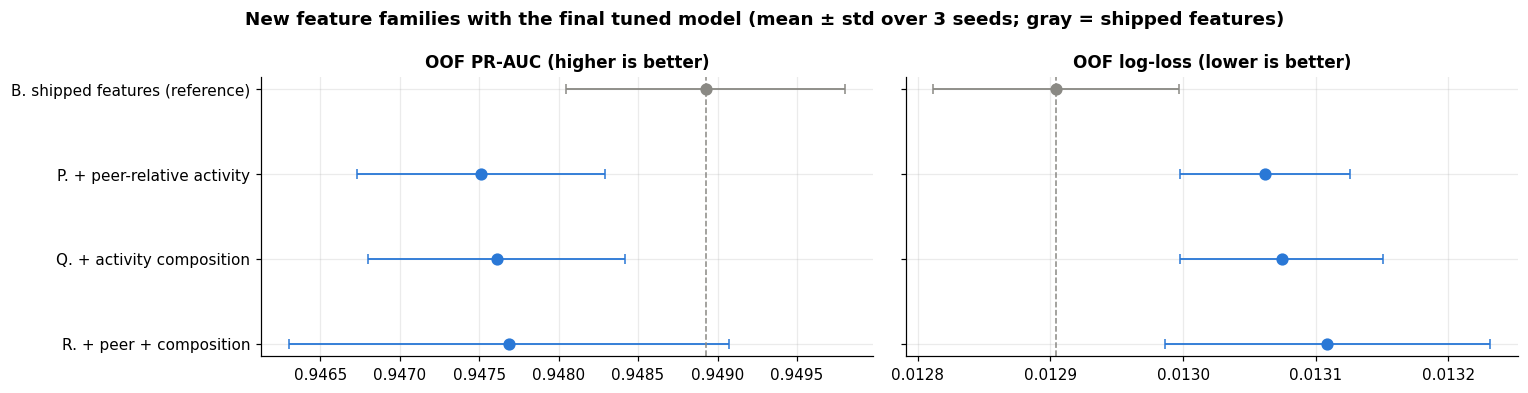

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, m, lab in zip(axes, ['oof_pr_auc', 'oof_log_loss'], ['OOF PR-AUC (higher is better)', 'OOF log-loss (lower is better)']):
    for i, n in enumerate(res.index[::-1]):
        ax.errorbar(res.loc[n, m], i, xerr=res.loc[n, f'{m}_std'], fmt='o', ms=7, capsize=3, lw=1.2, color=GRAY if n.startswith('B.') else BLUE)
    ax.set_yticks(range(len(res)), res.index[::-1] if ax is axes[0] else [''] * len(res)); ax.set_title(lab)
    ax.axvline(ref[m], color=GRAY, ls='--', lw=1)
plt.suptitle('New feature families with the final tuned model (mean ± std over 3 seeds; gray = shipped features)', fontweight='bold')
plt.tight_layout(); plt.show()

engineered features hold 40.8% of total gain in model R; top-30 features include 7 of them


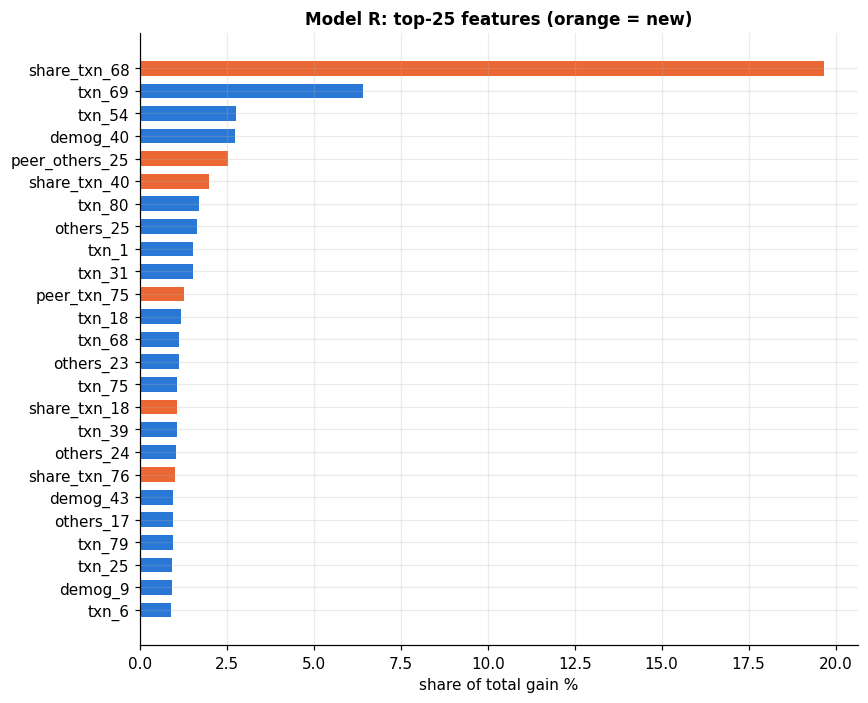

In [10]:
imp = MODELS['R. + peer + composition'].feature_importance('gain')
new = [c for c in imp.index if c.startswith(('peer_', 'share_')) or c in ('txn_entropy', 'txn_top_share')]
print(f'engineered features hold {imp[new].sum() / imp.sum():.1%} of total gain in model R; top-30 features include {sum(c in new for c in imp.index[:30])} of them')
top = (imp / imp.sum() * 100).head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=[ORANGE if c in new else BLUE for c in top.index], height=.65)
ax.set(xlabel='share of total gain %', title='Model R: top-25 features (orange = new)')
plt.tight_layout(); plt.show()

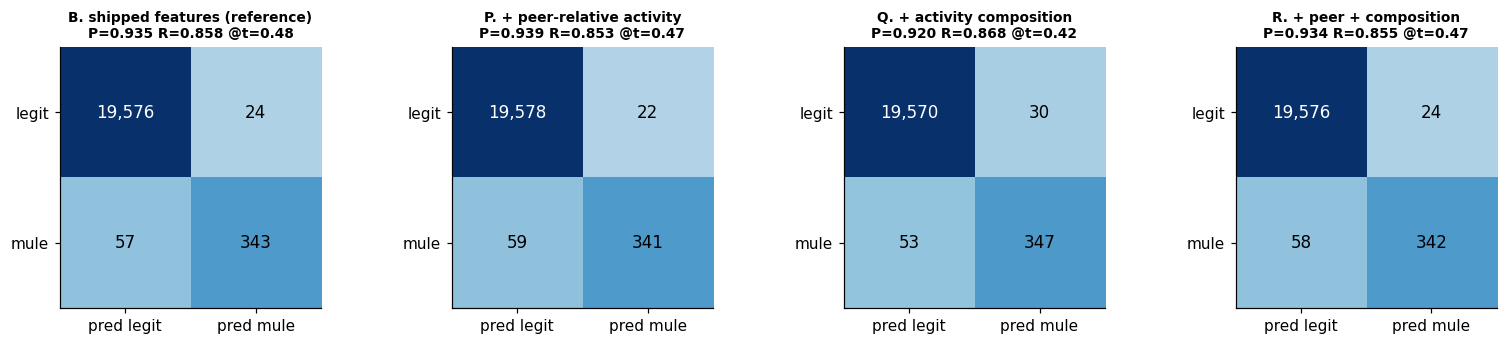

In [11]:
plot_confusions(list(RESULTS))

## 4. Conclusions

| Family | Result (OOF log-loss vs 0.01290 ± 0.00009) | Why | Decision |
|---|---|---|---|
| **Peer-relative activity** | 0.01306 (+1.2%, worse beyond noise); holdout +1% | The features *do* separate classes (mules sit 1–4 log-units above their segment on `txn_75`), but the raw `txn_75` already does. Segment baselines differ little compared with the size of the mule effect, so dividing by them adds no new information | not shipped |
| **Activity composition** | 0.01307 (+1.3%, worse beyond noise) | The hypothesis "mules use a narrow mix" is **contradicted by the data**: mules have *more* diverse transaction mixes (entropy ~1.6) while many legit accounts use a single type (entropy 0). The composition is already implicit in the raw columns | not shipped |
| **Both** | 0.01311 (+1.6%); holdout tie | The new features take **41% of the model's gain yet do not improve it**: they *substitute* for the raw columns (same information, re-expressed) and dilute column sampling (`colsample_bytree` 0.57), so each tree sees fewer of the original strong columns | not shipped |

**Feature engineering, overall (notebooks 03 + 03b):** seven feature families were built from structure discovered in
the anonymised data: aggregates, velocity, window ratios, missing flags, peer-relative activity, composition, and the
leaky counter shortfall. None of the leak-free ones beat seed-to-seed noise; the only big gain came from the leaky one,
excluded on principle. The raw behavioural columns already carry the signal that simple transformations can extract.
The features that would plausibly add information (pass-through ratio of money in vs out, credit-to-debit delay,
counterparty diversity) need to know which columns are credits and debits, which anonymisation hides.